In [1]:
import pandas as pd
!pip install XGboost
!pip install ucimlrepo
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, PrecisionRecallDisplay, average_precision_score
from xgboost import XGBClassifier


In [2]:
#Data loading via UCl repo
print("Fetching dataset from UCI ML Repository...")
bank_marketing = fetch_ucirepo(id=222)

Fetching dataset from UCI ML Repository...


In [3]:
#Extracting features and targets as pandas dataframe
X = pd.DataFrame(bank_marketing.data.features)
y = pd.DataFrame(bank_marketing.data.targets)


In [4]:
#Data cleaning and leakage prevention
# CRITICAL: Drop 'duration' to prevent data leakage.
# We do not know call duration before the call is made.
if 'duration' in X.columns:
    X.drop(columns=['duration'], inplace=True)
# The API returns 'y' as a DataFrame with a single column.
# Extract the series and map it to binary 1/0, checking first if it is still a DataFrame.
import pandas as pd
if isinstance(y, pd.DataFrame) and 'y' in y.columns:
    y = y['y'].map({'yes': 1, 'no': 0})
print(X.head())
print(y.head())

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  campaign  pdays  previous poutcome  
0     NaN            5   may         1     -1         0      NaN  
1     NaN            5   may         1     -1         0      NaN  
2     NaN            5   may         1     -1         0      NaN  
3     NaN            5   may         1     -1         0      NaN  
4     NaN            5   may         1     -1         0      NaN  
0    0
1    0
2    0
3    0
4    0
Name: y, dtype: int64


In [5]:
#feature segregation and splitting
# Identify numeric and categorical columns dynamically
numeric_cols = X.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X.select_dtypes(include=['category', 'object']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

# 2. Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Calculate Class Weight for XGBoost
# Formula: (number of negative samples) / (number of positive samples)
# This is XGBoost's equivalent to class_weight='balanced'
negative_cases = (y_train == 0).sum()
positive_cases = (y_train == 1).sum()
imbalance_ratio = negative_cases / positive_cases

print(f"Calculated scale_pos_weight: {imbalance_ratio:.2f}")


Numeric columns: ['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Calculated scale_pos_weight: 7.55


In [6]:
from sklearn.model_selection import RandomizedSearchCV

# 4. Preprocessing Pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# 5. Base Model Assembly
xgb_model = XGBClassifier(
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])
# 6. Hyperparameter Tuning using RandomizedSearchCV
print("\nRunning Hyperparameter Tuning (RandomizedSearchCV)...")
param_distributions = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__max_depth': [3, 4, 5, 6],
    'classifier__subsample': [0.8, 1.0],
    'classifier__colsample_bytree': [0.8, 1.0]
}

# We use average_precision (AUPRC) because the dataset is highly imbalanced
random_search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring='average_precision',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_
print(f"Best Parameters Found: {random_search.best_params_}")
# 6. Train and Evaluate
print("Training XGBoost model...")
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
print("\n--- XGBoost Classification Report ---")
print(classification_report(y_test, y_pred, target_names=["No Subscription", "Subscription"]))


Running Hyperparameter Tuning (RandomizedSearchCV)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters Found: {'classifier__subsample': 0.8, 'classifier__n_estimators': 300, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 1.0}
Training XGBoost model...

--- XGBoost Classification Report ---
                 precision    recall  f1-score   support

No Subscription       0.94      0.87      0.90      7985
   Subscription       0.36      0.56      0.44      1058

       accuracy                           0.83      9043
      macro avg       0.65      0.71      0.67      9043
   weighted avg       0.87      0.83      0.85      9043



In [7]:
# Calculate probability estimates for the positive class (Subscription)
y_proba = pipeline.predict_proba(X_test)[:, 1]

# Raise decision threshold to 70% confidence for premium lead targeting
custom_threshold = 0.70
y_pred_custom = (y_proba >= custom_threshold).astype(int)

print(f"\n--- Classification Report (Custom {custom_threshold} Threshold) ---")
print(classification_report(y_test, y_pred_custom, target_names=["No Subscription", "Subscription"]))


--- Classification Report (Custom 0.7 Threshold) ---
                 precision    recall  f1-score   support

No Subscription       0.92      0.95      0.94      7985
   Subscription       0.51      0.39      0.44      1058

       accuracy                           0.89      9043
      macro avg       0.72      0.67      0.69      9043
   weighted avg       0.87      0.89      0.88      9043



In [8]:
# 8. Business ROI Calculation
print("\n--- Business ROI Simulation ---")
# Assumptions
cost_per_call = 5     # $5 in agent time/resources per call
revenue_per_sub = 50  # $50 average revenue per successful subscription

# Scenario A: Call Everyone in the Test Set (Baseline)
calls_made_baseline = len(y_test)
subs_gained_baseline = y_test.sum()
profit_baseline = (subs_gained_baseline * revenue_per_sub) - (calls_made_baseline * cost_per_call)

# Scenario B: Use the Model's Targeting (70% Threshold)
calls_made_model = y_pred_custom.sum()
# True Positives: Customers we called who actually subscribed
subs_gained_model = ((y_test == 1) & (y_pred_custom == 1)).sum()
profit_model = (subs_gained_model * revenue_per_sub) - (calls_made_model * cost_per_call)

print(f"Scenario A (Call Everyone):")
print(f"  Calls Made: {calls_made_baseline}")
print(f"  Subscriptions Gained: {subs_gained_baseline}")
print(f"  Total Profit: ${profit_baseline:,.2f}")

print(f"\nScenario B (Model Targeted - 70% Threshold):")
print(f"  Calls Made: {calls_made_model} (Reduced call volume by {100 - (calls_made_model/calls_made_baseline)*100:.1f}%)")
print(f"  Subscriptions Gained: {subs_gained_model}")
print(f"  Total Profit: ${profit_model:,.2f}")

print(f"\nNet Financial Impact of Model: ${profit_model - profit_baseline:,.2f}")


--- Business ROI Simulation ---
Scenario A (Call Everyone):
  Calls Made: 9043
  Subscriptions Gained: 1058
  Total Profit: $7,685.00

Scenario B (Model Targeted - 70% Threshold):
  Calls Made: 798 (Reduced call volume by 91.2%)
  Subscriptions Gained: 409
  Total Profit: $16,460.00

Net Financial Impact of Model: $8,775.00



--- Generating SHAP Feature Explanations ---
Rendering SHAP Summary Plot...


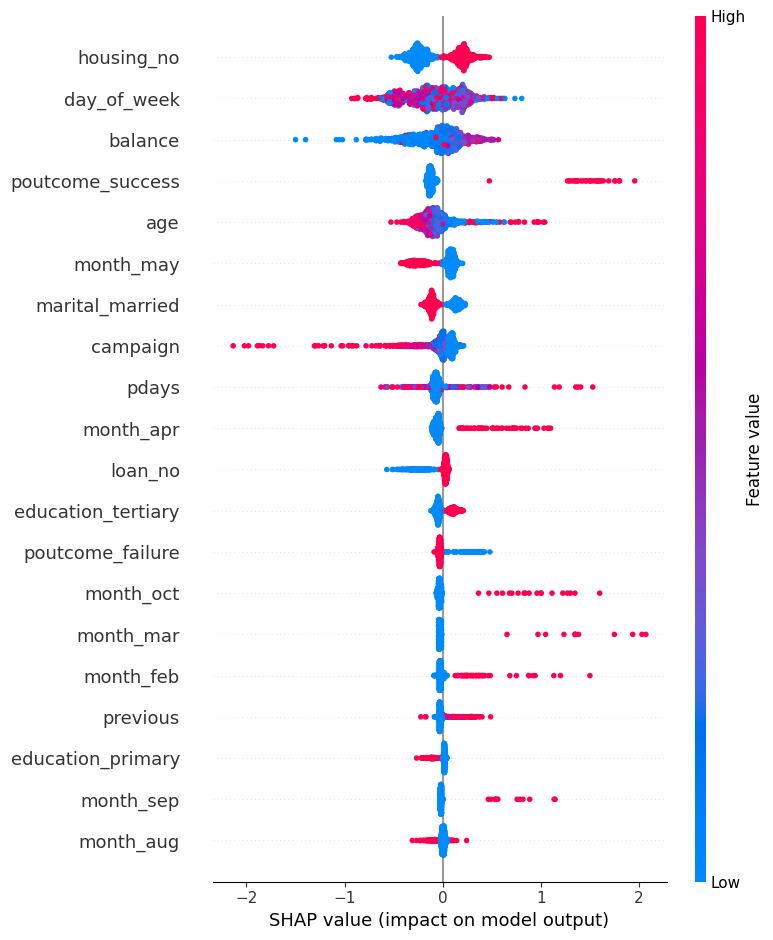

In [9]:
# 9. Model Explainability with SHAP
print("\n--- Generating SHAP Feature Explanations ---")

# Step 9a: Extract the fitted preprocessor and model from the best pipeline
fitted_preprocessor = best_model.named_steps['preprocessor']
fitted_xgb = best_model.named_steps['classifier']

# Step 9b: Transform a sample of the test data (using 1000 rows for speed)
# SHAP computation can be slow, so we take a representative sample
X_test_sample = X_test.sample(n=1000, random_state=42)
X_test_transformed = fitted_preprocessor.transform(X_test_sample)

# Step 9c: Get the actual feature names after One-Hot Encoding
# This ensures SHAP plot says "job_admin" instead of "feature 12"
feature_names = fitted_preprocessor.get_feature_names_out()

# Clean up feature names (optional, removes the 'num__' and 'cat__' prefixes from ColumnTransformer)
clean_feature_names = [name.split('__')[-1] for name in feature_names]

# Step 9d: Create the SHAP Explainer
# We use TreeExplainer because XGBoost is a tree-based model
explainer = shap.TreeExplainer(fitted_xgb)
shap_values = explainer.shap_values(X_test_transformed)

# Step 9e: Generate and display the SHAP Summary Plot
print("Rendering SHAP Summary Plot...")
# The summary plot shows global feature importance and the directional impact of each feature
shap.summary_plot(shap_values, X_test_transformed, feature_names=clean_feature_names)

In [10]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 20.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 45.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [11]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

# Page configuration
st.set_page_config(
    page_title="Bank Telemarketing ROI Dashboard",
    page_icon="🏦",
    layout="wide"
)

st.title("🏦 Predictive Lead Targeting & ROI Dashboard")
st.markdown("Optimize call center resources by adjusting the model confidence threshold and analyzing financial performance in real-time.")

# Load and train cached model & data
@st.cache_data
def load_and_train_model():
    bank_marketing = fetch_ucirepo(id=222)
    X = pd.DataFrame(bank_marketing.data.features)
    y = pd.DataFrame(bank_marketing.data.targets)

    if 'duration' in X.columns:
        X.drop(columns=['duration'], inplace=True)
    if isinstance(y, pd.DataFrame) and 'y' in y.columns:
        y = y['y'].map({'yes': 1, 'no': 0})

    numeric_cols = X.select_dtypes(include=['number']).columns.tolist()
    categorical_cols = X.select_dtypes(include=['category', 'object']).columns.tolist()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    negative_cases = (y_train == 0).sum()
    positive_cases = (y_train == 1).sum()
    imbalance_ratio = negative_cases / positive_cases

    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_cols),
            ('cat', categorical_transformer, categorical_cols)
        ]
    )

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            scale_pos_weight=imbalance_ratio,
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=1.0,
            random_state=42,
            n_jobs=-1
        ))
    ])

    pipeline.fit(X_train, y_train)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    return X_test, y_test, y_proba

with st.spinner("Fetching data and training XGBoost model... Please wait."):
    X_test, y_test, y_proba = load_and_train_model()

# --- SIDEBAR CONTROLS ---
st.sidebar.header("⚙️ Simulation Controls")
threshold = st.sidebar.slider("Conversion Probability Threshold", 0.0, 1.0, 0.70, 0.01)
cost_per_call = st.sidebar.number_input("Cost per Call ($)", value=5, min_value=1)
revenue_per_sub = st.sidebar.number_input("Revenue per Subscription ($)", value=50, min_value=1)

# --- BUSINESS SIMULATION LOGIC ---
y_pred_custom = (y_proba >= threshold).astype(int)

# Scenario A: Baseline (Call Everyone)
calls_made_baseline = len(y_test)
subs_gained_baseline = int(y_test.sum())
profit_baseline = (subs_gained_baseline * revenue_per_sub) - (calls_made_baseline * cost_per_call)

# Scenario B: Model Targeted
calls_made_model = int(y_pred_custom.sum())
subs_gained_model = int(((y_test == 1) & (y_pred_custom == 1)).sum())
profit_model = (subs_gained_model * revenue_per_sub) - (calls_made_model * cost_per_call)

call_reduction_pct = 100 - (calls_made_model / calls_made_baseline * 100) if calls_made_baseline > 0 else 0
net_financial_impact = profit_model - profit_baseline
conversion_rate = (subs_gained_model / calls_made_model * 100) if calls_made_model > 0 else 0

# --- MAIN DASHBOARD KPIS ---
st.subheader("📊 Key Performance Indicators")
col1, col2, col3, col4 = st.columns(4)

with col1:
    st.metric("Total Profit (Model)", f"${profit_model:,.2f}", delta=f"${net_financial_impact:,.2f} vs Baseline")
with col2:
    st.metric("Calls Made", f"{calls_made_model:,}", delta=f"-{call_reduction_pct:.1f}% volume", delta_color="inverse")
with col3:
    st.metric("Subscriptions Gained", f"{subs_gained_model:,}", delta=f"out of {calls_made_model} calls")
with col4:
    st.metric("Targeted Conversion Rate", f"{conversion_rate:.1f}%")

st.markdown("---")

# --- COMPARISON TABLE ---
st.subheader("📋 Scenario Breakdown & Comparison")
comparison_data = {
    "Metric": [
        "Total Outbound Calls",
        "Successful Subscriptions",
        "Total Cost of Calls",
        "Total Revenue Generated",
        "Net Profit"
    ],
    "Scenario A (Call Everyone / Baseline)": [
        f"{calls_made_baseline:,}",
        f"{subs_gained_baseline:,}",
        f"${calls_made_baseline * cost_per_call:,.2f}",
        f"${subs_gained_baseline * revenue_per_sub:,.2f}",
        f"${profit_baseline:,.2f}"
    ],
    f"Scenario B (Model @ {int(threshold*100)}% Threshold)": [
        f"{calls_made_model:,}",
        f"{subs_gained_model:,}",
        f"${calls_made_model * cost_per_call:,.2f}",
        f"${subs_gained_model * revenue_per_sub:,.2f}",
        f"${profit_model:,.2f}"
    ]
}

st.table(pd.DataFrame(comparison_data))

Writing app.py
